# TTK4115 – Helicopter Lab 2: Multivariable Control

**Post-processing of recorded experiments (Part II).** The plots follow the lab assignment, Section 2.2: reference tracking for pitch $p$ and elevation rate $\dot e$, and controller inputs $V_s$ and $V_d$.

The `input` directory contains the original MATLAB recordings. Plots are automatically saved as PNG files in the sibling `plots` directory. No MATLAB installation is required.

**Experiments available**

| Task | Control | Runs |
|---|---|---|
| 1 | LQR without integral action | `pure`, `qp5`, `qpd5`, `qep5`, `rvs5`, `rvd5` |
| 2 | LQR with integral action | `qp5`, `F5050`, `newintegralmaxF5050` |

**Important:** Run suffixes have been retained exactly as recorded. They indicate the intended experiment, but the full gain matrices for each historical run cannot be reconstructed from the saved time series alone. In particular, the provided note `Task2intergralreferencebysonqdp5 = F=0` refers to a filename not present in the archive; we have not assigned this setting to another file.

## 1. Setup and recorded signal format

Each run has three `.mat` files, all containing a matrix named `ans`:

- `encoder`: time, travel angle $\lambda$, travel rate $\dot\lambda$, pitch $p$, pitch rate $\dot p$, elevation angle $e$, elevation rate $\dot e$.
- `reference`: time, desired pitch $p_c$, desired elevation rate $\dot e_c$.
- `u`: time, voltage sum $V_s$, voltage difference $V_d$ (commands **before** motor saturation).

This channel ordering is confirmed by the provided generated Simulink C code, not inferred from the filenames. Logged angles are in radians, rates in rad/s, and commands in volts. The measurements have a 0.002 s sampling interval.

In [1]:
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from scipy.io import loadmat

# Works when launched from either the notebook folder or its parent.
notebook_dir = Path.cwd()
if not (notebook_dir / "input").is_dir():
    notebook_dir = notebook_dir / "notebook"
input_dir = notebook_dir / "input"
plot_dir = notebook_dir.parent / "plots"
plot_dir.mkdir(exist_ok=True)

runs = {
    "nointegral": ["pure", "qp5", "qpd5", "qep5", "rvs5", "rvd5"],
    "integral": ["qp5", "F5050", "newintegralmaxF5050"],
}
plt.rcParams.update({"font.size": 10, "axes.grid": True, "grid.alpha": 0.25})

In [2]:
def load_run(control, name):
    # Load the three recorded matrices for one experiment.
    prefix = f"task2{control}"
    files = {
        kind: input_dir / f"{prefix}{kind}byson{name}.mat"
        for kind in ("encoder", "reference", "u")
    }
    matrices = {key: loadmat(path)["ans"] for key, path in files.items()}
    for kind, rows in (("encoder", 7), ("reference", 3), ("u", 3)):
        if matrices[kind].shape[0] != rows:
            raise ValueError(f"Unexpected {kind} matrix in {files[kind].name}")
        if not np.allclose(matrices[kind][0], matrices["encoder"][0]):
            raise ValueError(f"Time stamps do not match for {control}/{name}")
    return matrices

# Quick check of all available recordings
print(f"{'Experiment':37} {'Duration [s]':>12} {'Samples':>10}")
for control, names in runs.items():
    for name in names:
        data = load_run(control, name)
        t = data["encoder"][0]
        print(f"{control + '/' + name:37} {t[-1]:12.2f} {len(t):10d}")

Experiment                            Duration [s]    Samples
nointegral/pure                              49.00      24501
nointegral/qp5                               38.31      19157
nointegral/qpd5                              45.77      22888
nointegral/qep5                              50.05      25028
nointegral/rvs5                              86.47      43235
nointegral/rvd5                              52.84      26419
integral/qp5                                 79.30      39653
integral/F5050                               85.61      42807
integral/newintegralmaxF5050                 60.83      30414


## 2. Plotting function

Each experiment gets one report-ready figure with the two tracking comparisons and the two control inputs. The references and measurements are overlaid as requested by the lab instructions. Figures are saved as PNG at 160 dpi.

In [3]:
def plot_run(control, name):
    data = load_run(control, name)
    t = data["encoder"][0]
    e, r, u = data["encoder"], data["reference"], data["u"]
    # Reduce drawing load while keeping the complete raw data unchanged.
    s = slice(None, None, max(1, len(t) // 12000))

    fig, ax = plt.subplots(3, 1, figsize=(11, 8.5), sharex=True, constrained_layout=True)
    ax[0].plot(t[s], r[1, s], '--', lw=1.25, label=r'Reference $p_c$')
    ax[0].plot(t[s], e[3, s], lw=1.15, label=r'Measured $p$')
    ax[0].set_ylabel('Pitch [rad]')

    ax[1].plot(t[s], r[2, s], '--', lw=1.25, label=r'Reference $\dot e_c$')
    ax[1].plot(t[s], e[6, s], lw=1.15, label=r'Measured $\dot e$')
    ax[1].set_ylabel('Elevation rate [rad/s]')

    ax[2].plot(t[s], u[1, s], lw=1.1, label=r'$V_s$')
    ax[2].plot(t[s], u[2, s], lw=1.1, label=r'$V_d$')
    ax[2].set_ylabel('Control input [V]')
    ax[2].set_xlabel('Time [s]')

    for a in ax:
        a.legend(loc='upper right', ncol=2, fontsize=9)
        a.set_xlim(t[0], t[-1])
    label = 'Task 1: LQR' if control == 'nointegral' else 'Task 2: Integral LQR'
    fig.suptitle(f'{label} – {name}', fontsize=14)
    fig.savefig(plot_dir / f'{control}_{name}.png', dpi=160)
    plt.show()

## 3. Task 1 – LQR without integral action

Six available tuning experiments. Compare the reference tracking, transient response and control effort. Note that joystick commands differ between experiments, so these are **not identical-input step-response tests**.

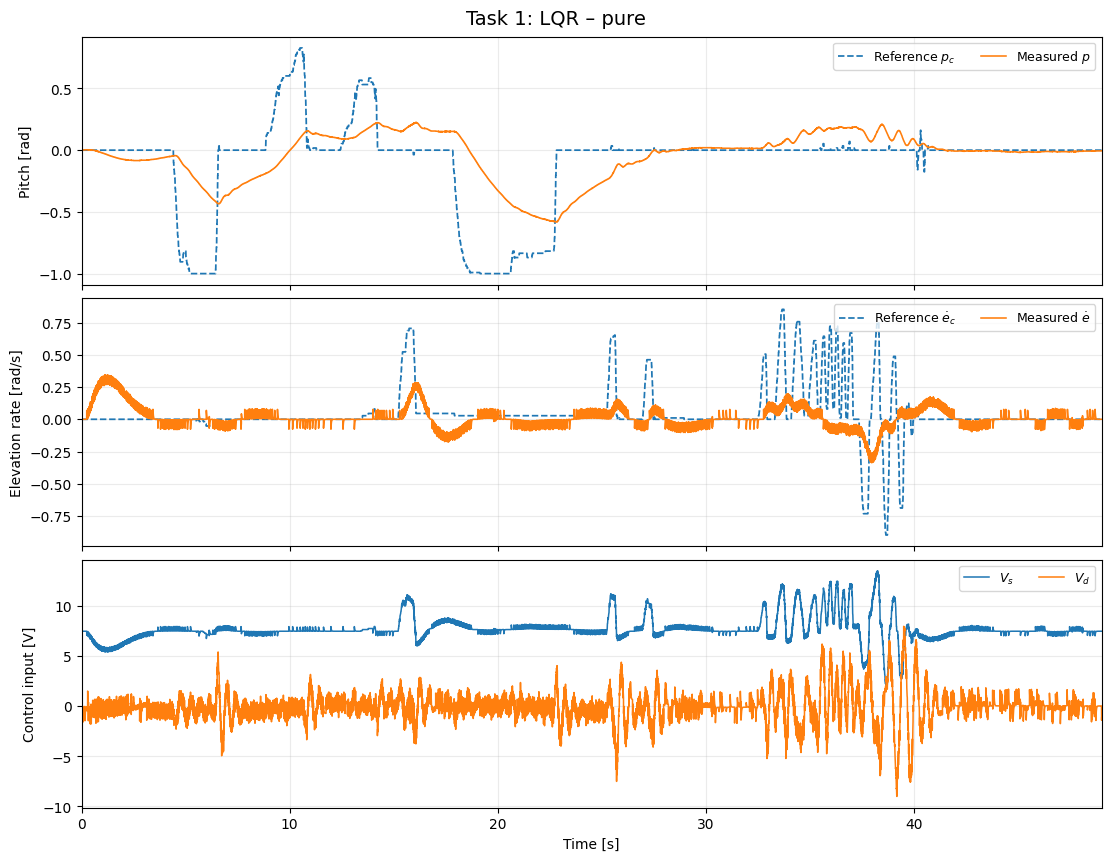

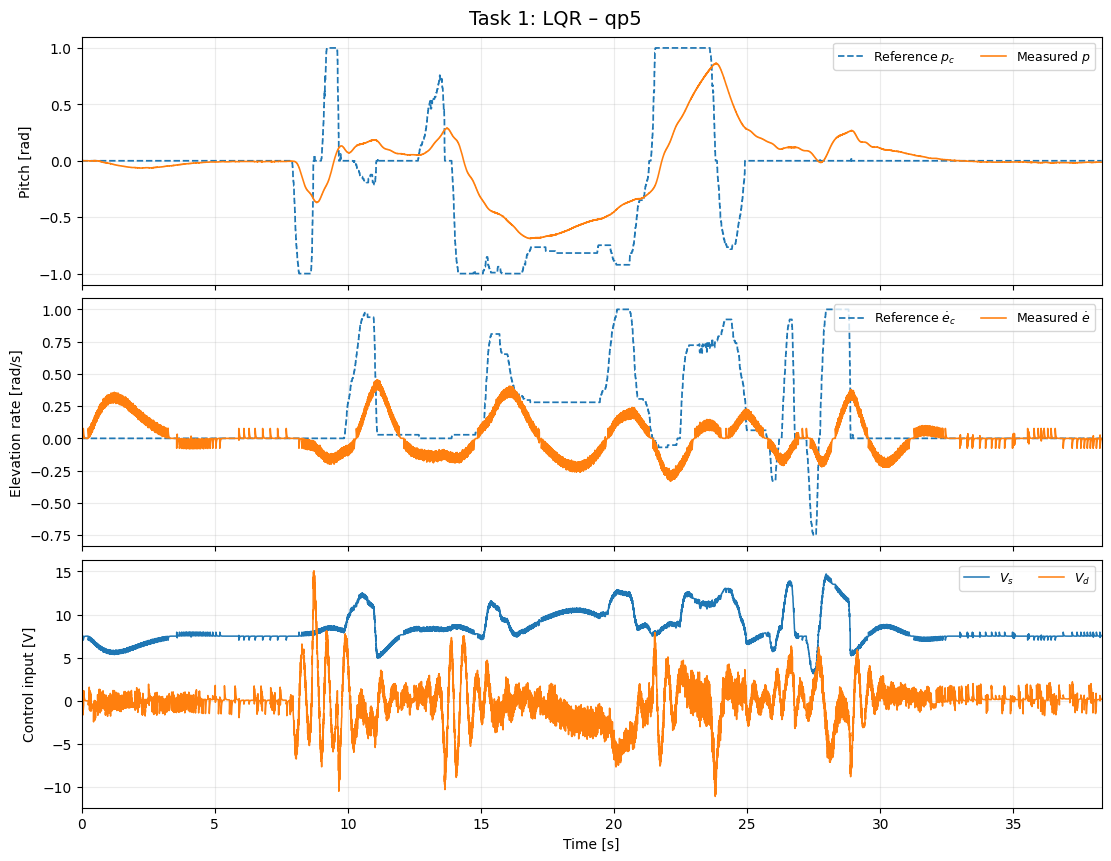

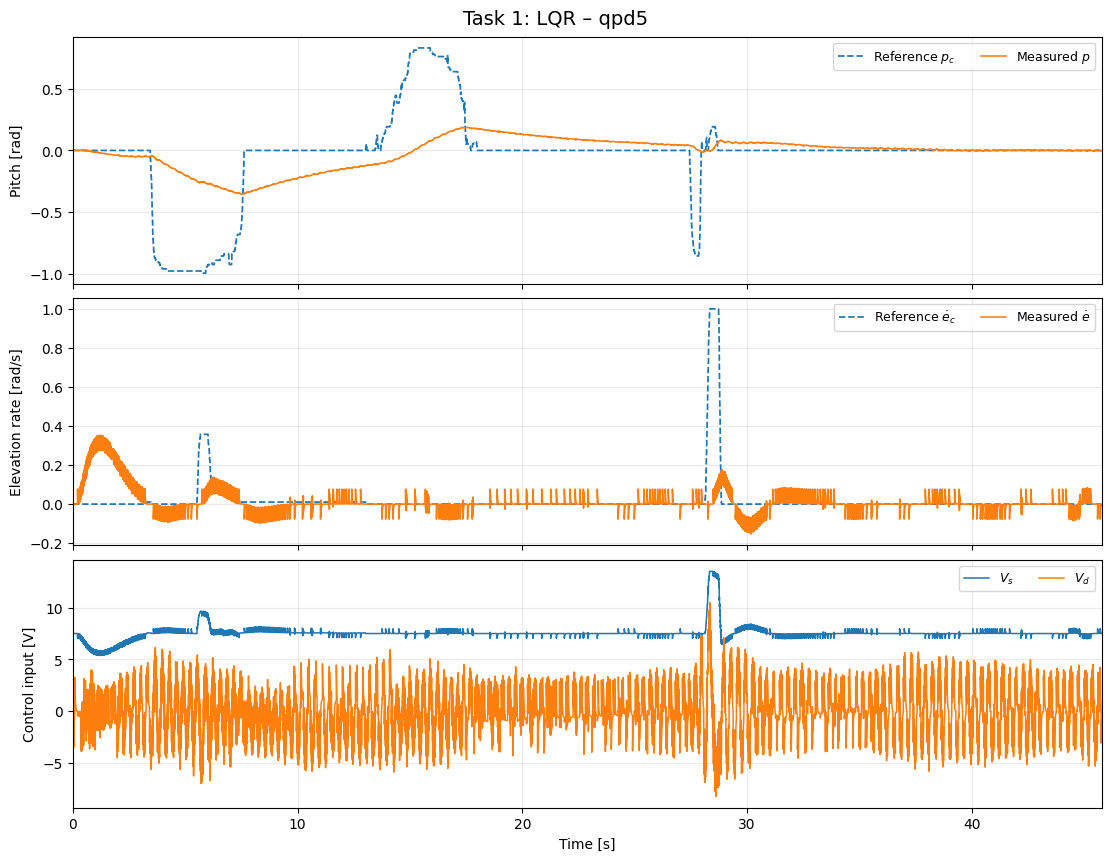

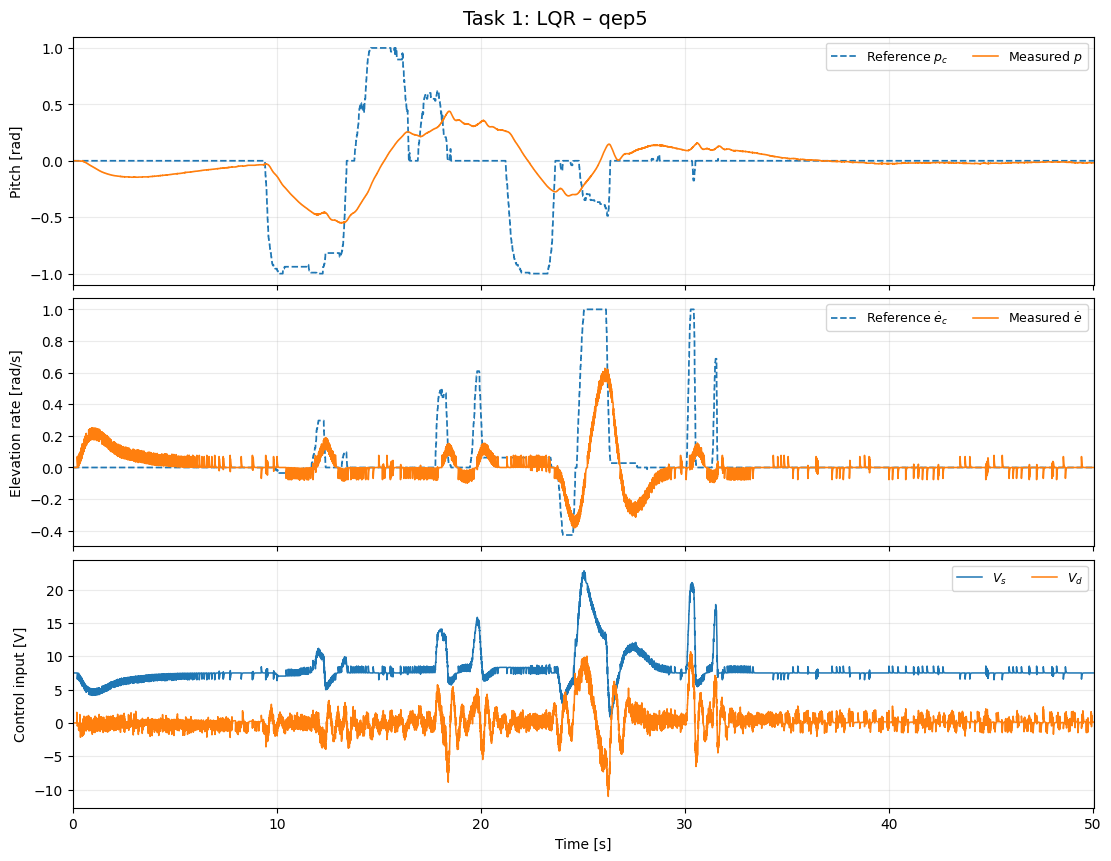

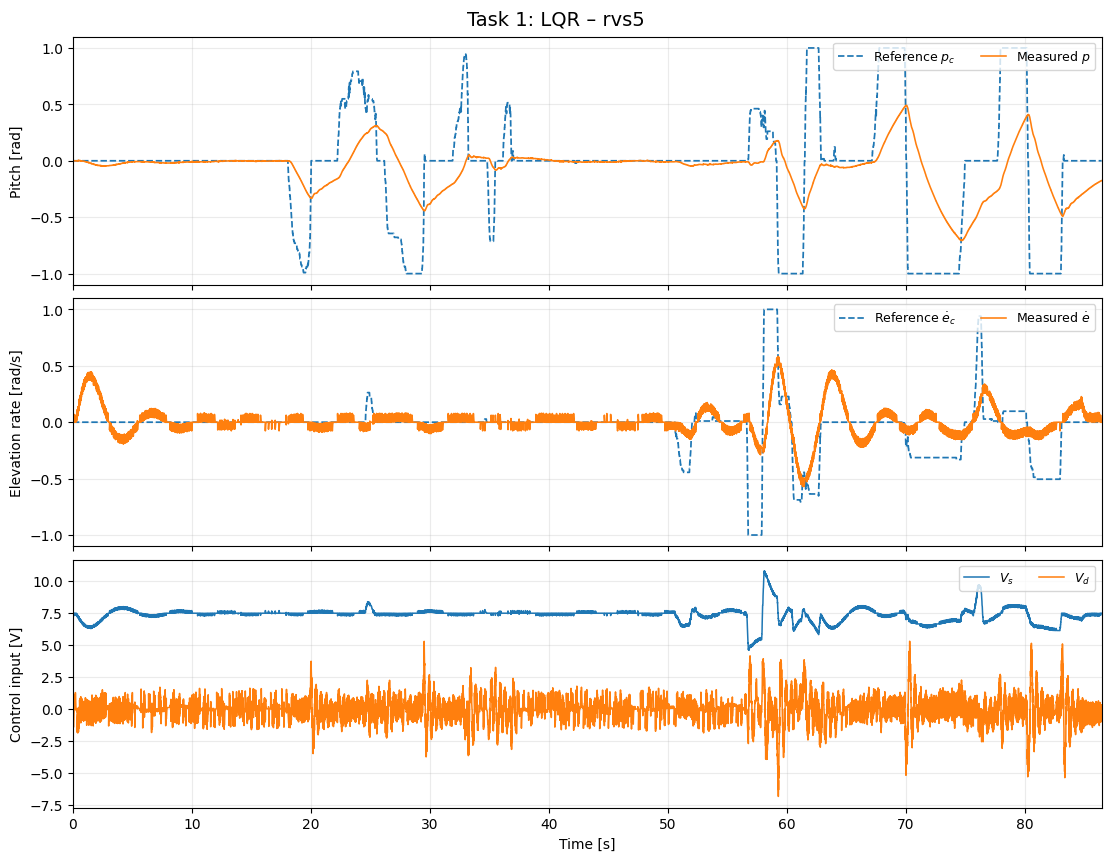

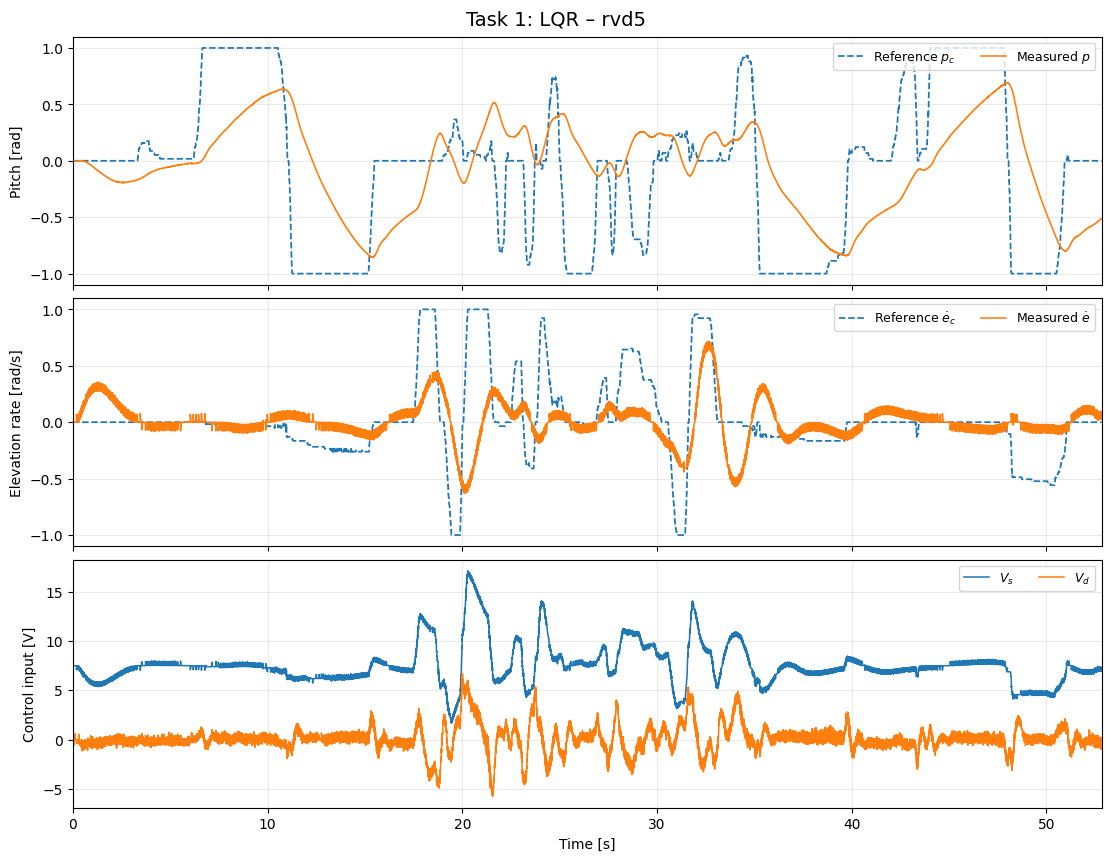

In [4]:
for name in runs["nointegral"]:
    plot_run("nointegral", name)

## 4. Task 2 – LQR with integral action

Three available experiments. Compare tracking performance and input activity, paying particular attention to any steady-state error and oscillations. The historical feedforward matrix for every run is **not** independently identifiable from the recordings.

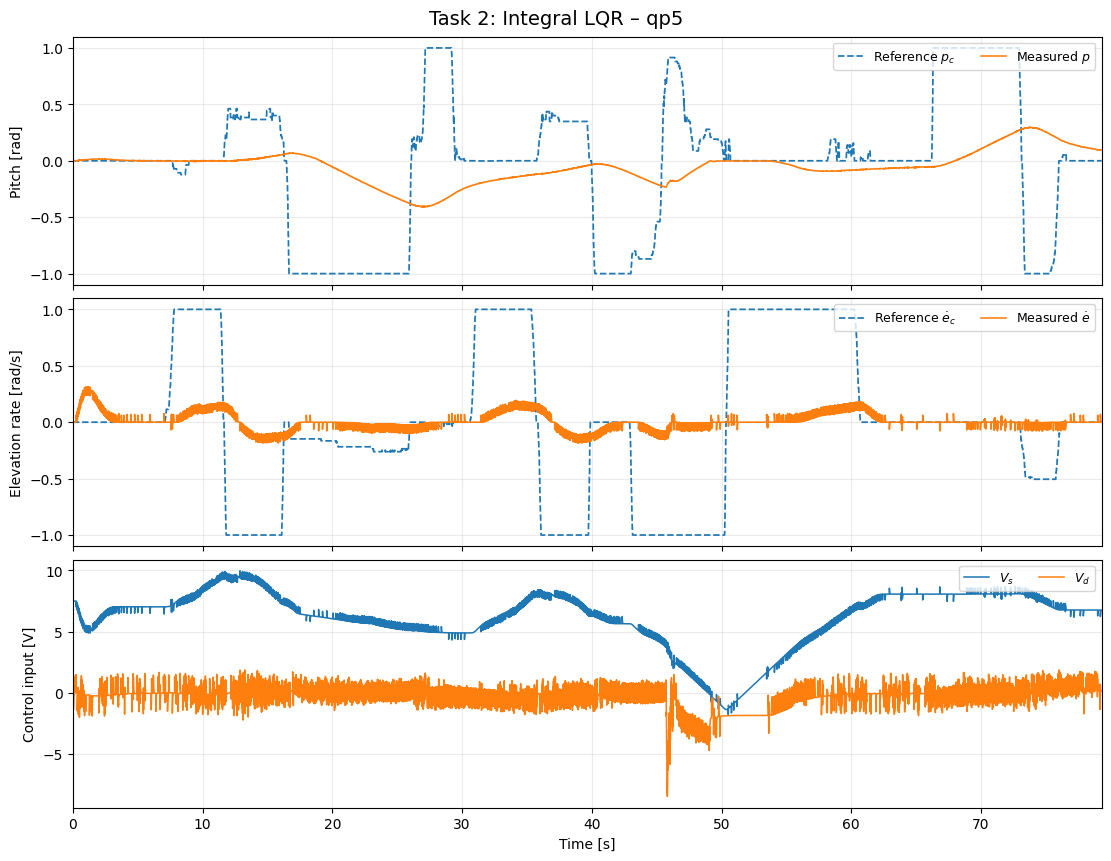

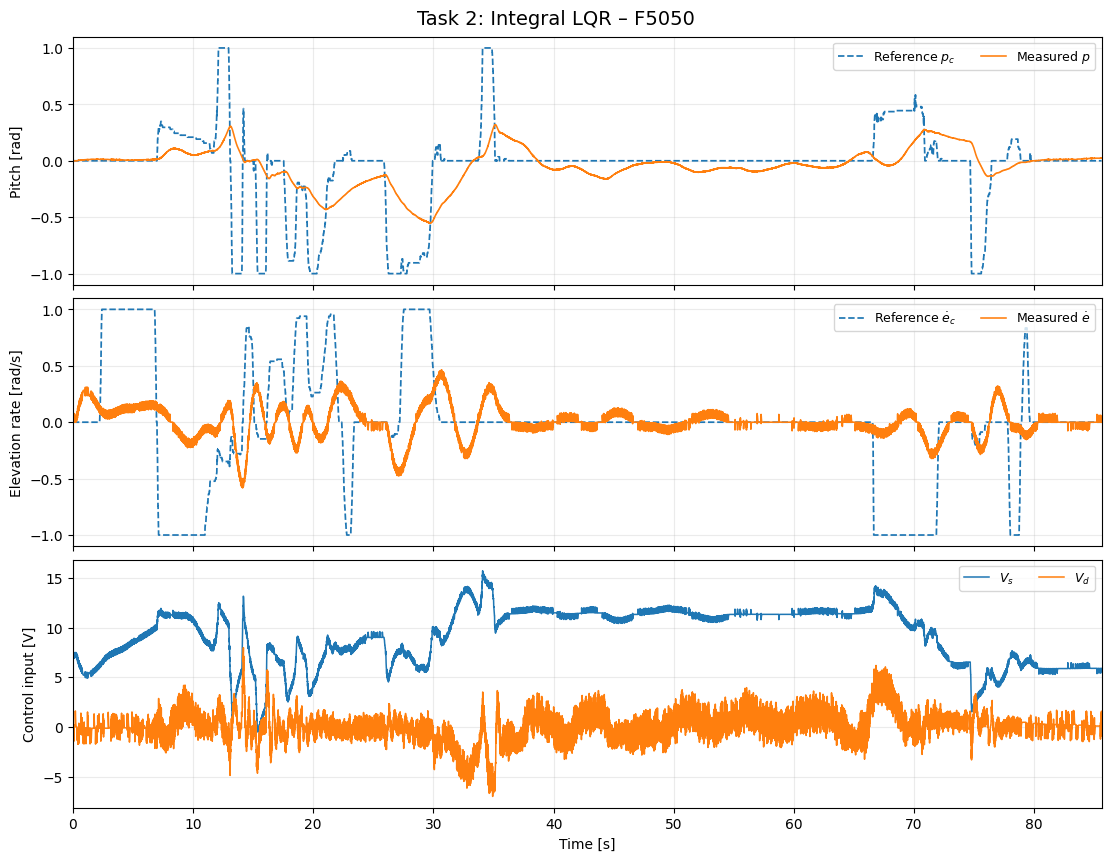

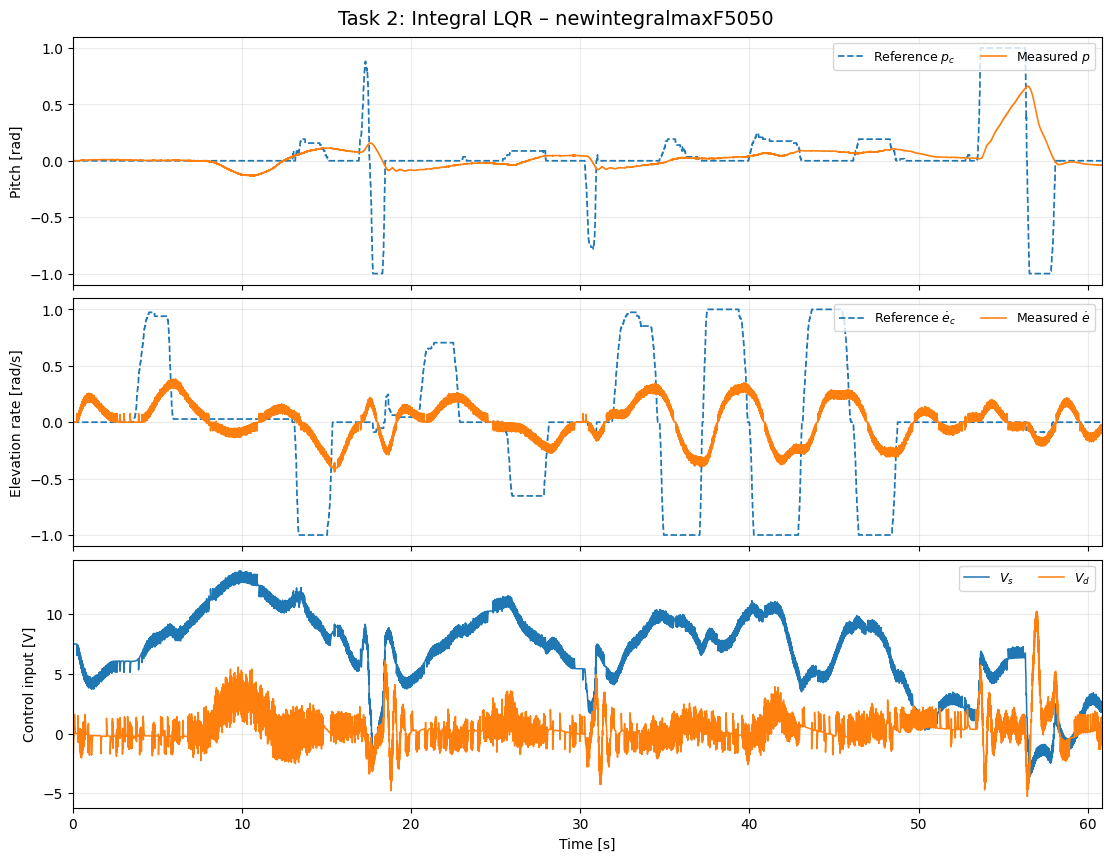

In [5]:
for name in runs["integral"]:
    plot_run("integral", name)

## 5. Compact overview figures

These overviews show the same two tracking variables for every available run. Because joystick inputs were manually varied, comparisons should consider differences in the reference signals as well as the measured responses.

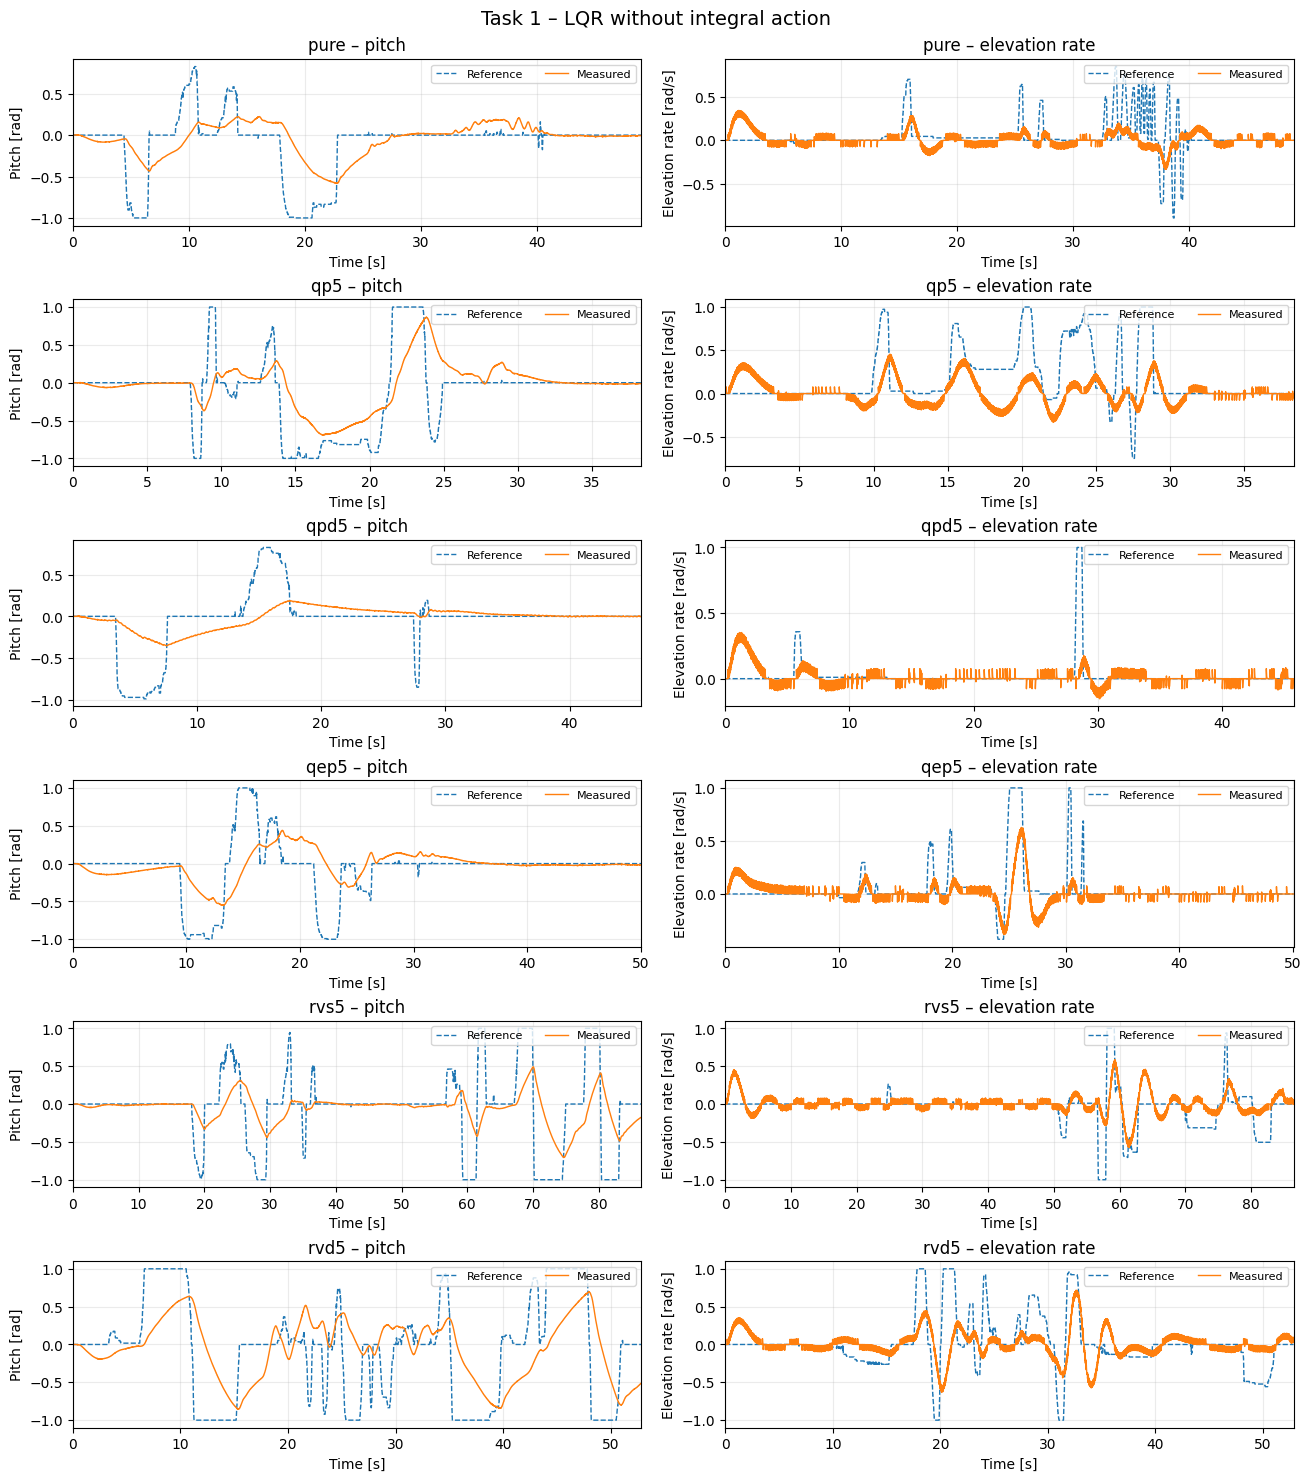

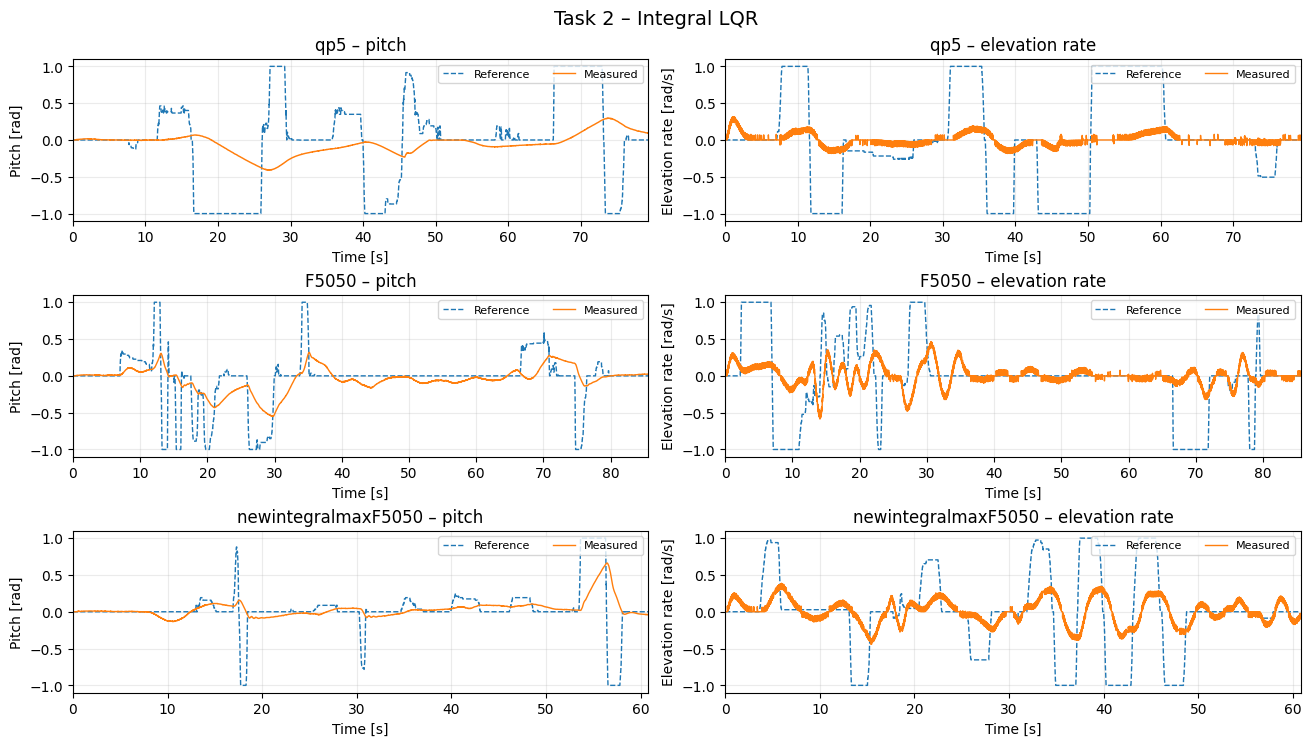

In [6]:
def plot_overview(control):
    names = runs[control]
    fig, axs = plt.subplots(len(names), 2, figsize=(13, 2.45 * len(names)),
                            constrained_layout=True, squeeze=False)
    for row, name in enumerate(names):
        data = load_run(control, name)
        t, e, r = data["encoder"][0], data["encoder"], data["reference"]
        s = slice(None, None, max(1, len(t) // 10000))
        for col, (ref_row, enc_row, ylabel) in enumerate([
            (1, 3, 'Pitch [rad]'), (2, 6, 'Elevation rate [rad/s]')
        ]):
            ax = axs[row, col]
            ax.plot(t[s], r[ref_row, s], '--', lw=1.0, label='Reference')
            ax.plot(t[s], e[enc_row, s], lw=1.0, label='Measured')
            ax.set_title(f'{name} – {"pitch" if col == 0 else "elevation rate"}')
            ax.set_ylabel(ylabel)
            ax.set_xlabel('Time [s]')
            ax.legend(loc='upper right', fontsize=8, ncol=2)
            ax.set_xlim(t[0], t[-1])
    title = 'Task 1 – LQR without integral action' if control == 'nointegral' else 'Task 2 – Integral LQR'
    fig.suptitle(title, fontsize=14)
    fig.savefig(plot_dir / f'{control}_overview.png', dpi=160)
    plt.show()

plot_overview('nointegral')
plot_overview('integral')

## 6. Notes for the lab report

- **Task 1:** Discuss the effect of adjusting the LQR weighting matrices $Q$ and $R$. The files document the experimental runs, but the final MATLAB initialization scripts do not preserve each run's exact historical weights.
- **Task 2:** Discuss how integral action affects steady-state tracking, transients and control effort. `F5050` and `newintegralmaxF5050` are separate recordings; do not assume their only difference is the integral limit without additional evidence.
- **Logging:** The compiled Simulink `To File` blocks use the same output filename on every execution until it is manually changed. This can overwrite a previous experiment.
- **Missing model:** `heli_q8lab2new.slx` is absent from the supplied archive. Neither `heli_q8lab2new.slxc` nor the generated QUARC files are substitutes for the editable main Simulink model.
- **Unresolved note:** `Task2intergralreferencebysonqdp5 = F=0` does not match an available filename. We have kept this note but have not applied it to the `integral/qp5` data.
- **MATLAB script issue:** `init_heli_3_10lab2nointegral.m` constructs the second row of `K` using `K(1,3)` where `K(2,3)` would ordinarily be expected. This may introduce an unintended coupling; whether the historical experiments used this exact version cannot be determined.